## Common data problems

Data science work flow:

- Access raw data
- Explore and Process Data
- Extract Insights using visualizations or predictive models
- Report Insights with dashbords or reports

### Why do we need to clean data?
Dirty data can appear because of duplicate values, mis-spelling, data type parsin errors and legacy systems.

Without making sure that data is properly cleaned in the exploration and processing phase we will surely compromise the insights and reports subsequently generated.

## Data type constraints

Ex if a revenue column is a strin, summing across all sales returns one large concatenated string...

Remove $ from Revenue columna change dtype

        sales['Revenue'] = sales['Revenue'].str.strip('$)
        sales['Revenue'] = sales['Revenue'].astype('int')

### The assert statement

Verify that the Revenue column is now an integer by using the assert statement, which takes a condition as input, and returns nothing if that condition is met, and an error if it is not

    assert sales['Revenue'].dtype == 'int



## Numeric or categorical

Ex a column marriage_status with number classes. It will be imported as type integer, which could lead to  misleading results when trying to extract some statistical summaries. 

    .astype('category')

## Data range constraints

for example future dates that are not allowed, or rating our of the given range.

For the date problem, we can use the dataetime package to get today's data and use it to filter the data.

    today_date = dt.date.today()
    user_signups[user_signups['subscription_date'] > dt.date.today()]

We need to pay attention to the range of our data!

How to deal with out of range data?

- dropping data - however, depending on the size of your out of range data, you could be losing out on essential information. Only drop data when a small proportion of your dataset is affected by out of range values. However, you really need to understand your dataset before deciding to drop values!!

- Setting custom min and maximums
- Treat as missing and impute
- Setting custom value depending on bussiness assumption


        movies[movies['avg_rating'] > 5]

You can drop values using filtering

        movies = movies[movies['avg_raing >= 5]]

Or drop values using .drop()

        movies.drop(movies[movies['avg_rating'] > 5].index, inplace=True)

Asser results

        assert movies['avg_rating'].max() <= 5 



Depening on our assumptions behind our data, we can also change the out of range values to a hard limit.

For ex, here we set any value to 5 if it goes beyond it.

        movies.loc[movies['avg_rating'] > 5, 'avg_rating'] = 5


### Converting to date

        pd.to_datetime(df['col']).dt.date

Without the pd.to_timetime() we'd have to provide information about the date's format as a string, so it's jsut as easy to do it this way.

### Date range

You can either drop the out of range dates as we did ealier or hardcode dates with upper limit with .loc()

        user_signups.loc[user_signups['subsciption_date'] > today_date, 'subscription_date'] = today_date

check the results

        asser user_signups.subscription_date.max().date() <= today_date

## Uniqueness constraints

Duplicate values - rows that have identical values across all columns. 

Why do the happen?

- data entry and human error
- bugs and design errors in business processes or data pipelines
- oftenmost: from joining and consolidating data from vaious resources, which coult retain duplicate values.

How do find them

                duplicates = height_weight.duplicated() 

creates a boolean values. we can us it to filter

                height-weight[duplicates]

Important arguments

- subset: list of column names to check for duplicates.
default:returns only the non-first complete duplicates across all columns

- keep (first, last or False) : whether to keep first, last or all duplicate values

        column_names = ['first_name', 'last_name', 'address']
        duplicates = height_weight.duplicates(subset=column_names, keep= False)

How to find duplicates rows?

        height_weight[duplicates].sort_values(by='first_name')

How to treat duplicate values?

.drop_duplicates()

same arguments as for .duplicated()

        height_weight.drop_duplicates(inplace=True)

here we are dropping complete duplicates only

## The .groupby() and .agg() methods

when chained they group by a set of common columns and return statistical values for specific columns when the aggregation is being performed

        column_names = ['first_name', 'last_name', 'address']
        summaries = {'height':'max', 'weight': 'mean'}
        height_weight = height_weight.groupby(by=column_names).agg(summaries).reset_index()

## Membership constraints

Categories - predefined finite set of categories

We could have inconsistency in our categorical data. 

There are specific solutions for different types of inconsistencies.

- dropping data
- remapping categories
- inferring categories

It is good to keep a log with all possible values of your categories. For example a dataframe containing the correct options! It makes dealing with inconsistencies easier.

## A note on joins

Anti Join - takes in two dataframes A and B, and return data from one dataframe that is not contained in another.

ex A is the left one - we return the columns of A and B for values on in A of the common column between them being joined on

ex a left anti join essentially returns all the data in study data with inconsistent blood types. 

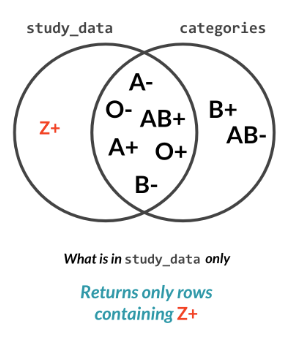


And an inner join returns all the rows containing consistent blood types signs. 

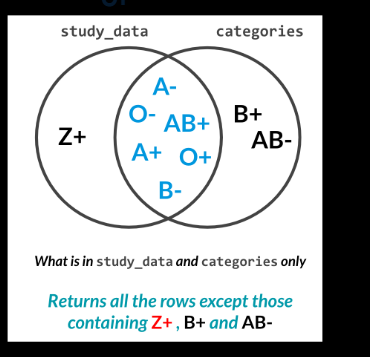

## Finding inconsistent categories

difference() är en metod för set som returnerar en ny mängd med de element som finns i den första mängden men inte i den andra

        inconsistent_categories = set(study_data['blood_type']).difference(categories['blood_type'])

this returns all the cateogires in blood_type that are not in categories

We then find the inconsistent rows by finding all the rows of the blood_type columns that are equal to inconsistent cateogories by using the isin method. This returns a series of boolean values.

        inconsistent_rows = study_data['blood_type'].isin(inconsistsent_cateogories)

We then subset the study_data dataframe based on these boolean values, and voila we have our inconsistent data.

#### Dropping inconsistent categories
we just use the tilde symbol while subsetting which returns everything except inconsistent rows.

        consistent_data = study_data[~inconsistent_rows]

## Categorical variables

It is not only membership constraints that is a problem.

### value inconsistency

capitalization for example
To check a series:

    Series.value_counts()

Getting value counts on DataFrame

    marriage_status.groupby('marriage_status').count()

## Value consistency
.str.upper() 

.str.lower()

leading or trailing whitespaces

.str.strip()

## Collpasing data into categories

- pd.qcut(df[''], q= , labels)

- pd.cut(df[''] , bins=, labels=)

- mapping:

    mapping = {}
    devices[] = devices[].replace(mapping)
    devices[].unique()

## Cleaning text data

names, phonenr, addresses

problems

- data inconsistency
- fixed length violations
- typos

ex fixing a phone number column

    phones['Phone number'] = phones['Phone number'].str.replace('+', '00')

    phones['Phone number'] = phones['Phone number'].str.replace('-', '')
    
replacing all phone numbers below 9 digits to NaN

    digits = phones['Phone number'].str.len()
    phones.loc[digits < 10, 'Phone number'] = np.nan

another example

    airlines['full_name'] = airlines['full_name'].str.replace('Ms.', '')

    assert airlines['full_name'].str.contains('Ms.|Mr.|Miss|Dr.').any() == False


## More complicated examples

using regex - regular expressions, gives us the ability to search for any pattern in text data, like only digits for example.

    phones['Phone number'] = phones['Phone number'].str.replace(r'\D+', '')

regex is immensely useful for difficult string cleaning tasks

## Uniformity

Unit uniformity (like no mixing celsius and fahrenheit, or kg and stones etc etc)

ex

we can do a scatterplot to see the values 

### treating temperature data

    temp_fah = temperatures.loc[temperatures['Temperature'] > 40, 'Temperature']
    temp_cels = (temp_fah - 32) *(5/9)
    temperatures.loc[temperatures['Temperature] > 40, 'Temperatures] = temp_cels

making sure that our conversion was correct with an assert statement

    assert temperatures['Temperature'].max() < 40

### treating date data

MM-DD-YY

MONTH D, YYYY

#### Datetime formatting

datetime is useful for representing dates

pandas.to_datetime()  
- can recognize most formats automatically
- sometimes fails with erroneous or unrecognizable formats

    birthdays['Birthday'] = pd.to_datetime(birthdays['Birthday'], errors='coerce')

the errors='coerce' will return missing values for dates that couldn't be identified and converted instead of a value error. 

We can also convert the format of a datetime column using the dt.strftime() method, which accepts a datetime format of your choice. 

    dt.strftime("%d-%m-%Y)

#### Treating ambiguous date data

However, a common problem is having ambiguos dates with vague formats. is 2019-03-08 in august or march? 
Unfortunately, there is no clear cut way to spot this inconsistency or to treat it.

Depending on the size of the dataset and suspected ambiguities, we can either:

- convert these dates to NA and treat accordingly.
- Infer format by understanding the data source
- Infer format by understanding previous and subsequenct data in DataFrame

It is essential to properly understand where your data comes from, before trying to treat it, as it will make these decisions much easier.




## Cross field validation

for diagnosing dirty data.

The use of muiltiple fields in a dataset to sanity check data integrity. 


    sum_classes = flights[['economy_class', 'business_class', 'first_class']].sum(axis=1)   for row summing
    passanger_equ = sum_classes == flights['total_passengers']

find and filter out rows with inconsistent passenger totals

    inconsistent_pass = flights[~passanger_equ]
    consistent_pass = flights[passenger_equ]

#### Another example

    used['Birthday'] = pd.to_datetime(users['Birthday'])
    today = dt.date.today()
    age_manual = today.year - users ['Birthday'].dt.year
    age_equ = age_manual == users['Age']

    inconsistent_age = users[~age_equ]
    consistent_age = users[age_equ]

### What to do when we catch inconsistencies?
just like all data cleaning problems, there is no one-size fits all solution. OFten the best solution requires an indepth understanding of our dataset and the different sources feeding into it.

- dropping data
- set to missing and impute
- apply rules from domain knowledge

## Completeness

Missing data is one of the most common and most important data cleaning problems. 

What is missing data? when no data is stored for a variable in an observation

Most commonly represented as NA or NaN, but can take on arbitrary values like 0 or . 

    isna()
    isna().sum()

### Missingno
Useful package for visualizing and understanding missing data.

    import missingno as msno

    msno.matrix(airquality)
    plt.show()

The matrix will show how missing values are distributed across a column.

Dig deeper

    missing = airquality[airquality['CO2].isna()]
    complete = airquality[~airquality['CO2].isna()]

then use the describe() method on each of these new dataframes

We can see that for all the missing values they occur at really low temperatures. We can confirm this visually with the missingno package

    sorted_airquality = airquality.sort_values(by = 'Temperature')
    msno.matrix(sorted_airquality)

We will see all the missing values on top of CO2, because values are sorted from smallest to largest by default.
This essentially confirms that CO2 measurements are lost for really low temperatures. Must be a sensor failiure. 

## Missingness types 

- Missing Completely at Random (MCAR) - ex data entry errors
- Missing at Random (MAR) - there is a relationship to other observed values
- Missing Not at Random (MNAR) - systematic relationship between missing data and unobserved values. We have no way of telling just by looking at the data

## Dealing with missing data

simple approaches

- drop
- impute with statistical measures

complex approaches
- imputing using an algorithmic approach
- impute with ML models

        dropping 
            airquality_dropped = airquality-dropna(subset=['CO2'])
            airquality_dropped.head()
        replacing
            co2_mean = airquality['CO2'].mean()
            airquality_imputed = airquality.fillna({'CO2': co2mean})


## Comparing strings

Minimum edit distance - a systematic way to identify how close 2 strings are. The least possible amount of steps that could get us from one word to another.

Operations:
- insertion
- deletion
- substitution
- transposition

The minimum edit distance is a count of the operations needed. 

Kevenshtein -general form of string matching using thefuzz package.

## Simple string comparison

In [9]:
# to compare between two strings
from thefuzz import fuzz

fuzz.WRatio('Reeding', 'Reading')

86

The output is a score from 0 - 100. 100 being an exact match. 

### Extract function
You can use the extract-function which takes in a string, an array of strings and the number of possible matches to return ranked form highest to lowest. 

It returns a list of tuples with 3 elements, the first on being the matching string, the second one being its similarity score, and the third one being its index in the array.

In [13]:
import pandas as pd
from thefuzz import process

string = 'Houston Rockets vs Los Angeles Lakers'
choices = pd.Series(['Rockets vs Lakers', 'Lakers vs Rockets', 
            'Houston vs Los Angeles', 'Heat vs Bulls'])

process.extract(string, choices, limit=2)

[('Rockets vs Lakers', 86, 0), ('Lakers vs Rockets', 86, 1)]

## Collapsing categories with string similarity

We saw earlier : .replace() to collapse 'eur' to 'Europe'

What if we had so many inconsistent categories that a manual replacement is simply not feasible?

We can easily do that with string similarity!

For each correct category, finding potential matches in states with typoes. For each potential match match. If high similarity score, replace type with correct category. 

    for state in categories['state']:
        matches = process.extract(state, survey['state'], limit = survey.shape[0])

        for potential_match in matches:
            if potential_match[1] >= 80:

            survey.loc[survey['state'] == potential_match[0], 'state'] = state

When using this method, you need to determine the cutoff point for similarity. Too high you risk missing some types, too low similarity you risk including the wrong categories. And 




## Record linkage

When joins won't work

Duplicate values in two dataframes, they are games happening at the same time, no common unique identifier between them, and the events are differently names, a regular join or merge won't work. This is where record linkage comes in. It is more complex than using a traditional join.


The act of linking is the act of linking data form different sources regarding the same entity. 

Generally, we clean two or more DataFrames, generate pairs of potentially matching records, score these pairs using string similarity and other similarity metrics, and link them.

All of these steps can be achieved with the recordlinkage package.

### Blocking
creates pairs based on a matching column, reducing the number of possible pairs.

Step 1: Generating pairs blocked on state:

    import recordlinkage
    indexer = recordlinkage.Index()
    indexer.block('state')
    pairs = indexer.index(A, B)

   

Step 2: Comparison step and getting scores

find exact matches for pairs of date_of_birth and state:

    compare_cl = recordlinkage.Compare()

    compare_cl.exact('date_of_birth', 'date_of_birth', label='date_of_birth')
    compare_cl.exact('state', 'state', label='state')

find similar matches for pairs of surname and address_1 using string similarity:

    compare_cl.string('surname', 'surname', threshold=0.85, label='surname)
    compare_cl.string('address_1', 'address_1', threshold=0.85, label='address_1')

find the matches (potential duplicates):

    potential_matches = compare_cl.compute(pairs, A, B)

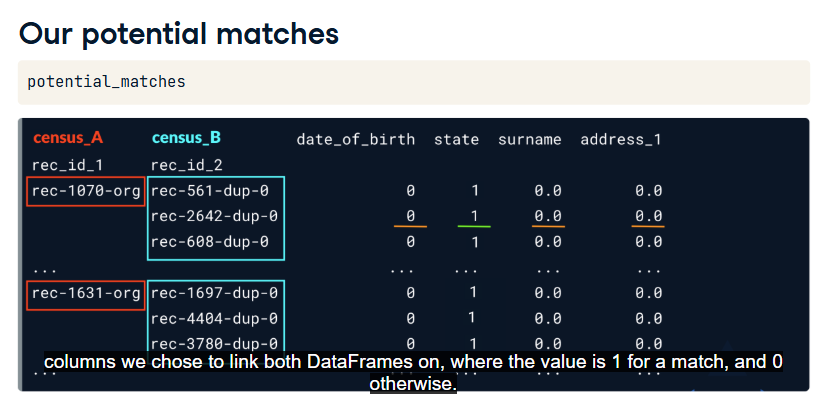


### Last step: Linking DataFrames

The first step in linking DataFrames, is to isolate the potentially matching pairs (the ones that could be dupliciates?)

### finding matching pairs

To find potential matches, we just filter for rows where the sum of row values is higher than a certain bymber of columns, in this case 4.

    potential_matches[potential_matches.sum(axis=1 => 3)]

The output is row indices between A and B that are most likely duplicates:

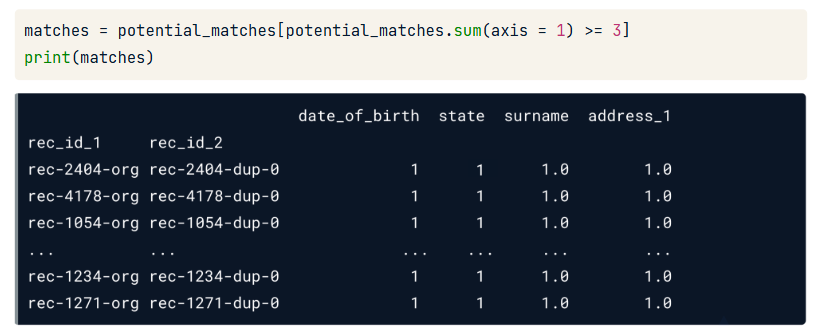

Our next step is to extract one of the index columns and subsetting its associated DatFrame to filter for duplicates. 

Here we choose the second index column, which represents row indices of B. We want to extract those indices, and subset B on them to remove duplicates with a before appending them together. 

Getting indixes from B only:

    duplicates_rows = matches.index.get_level_values(1)

1 is the order of B in matches. 

Finding duplicates in B:

    B_duplicates = B[B.index.isins(duplicate_rows)]

Finding new rows (non-duplicates):

    B_new = B[~B.index.isin(duplicates_rows)]

Link the DataFrames:

    full = pd.concat([A, B_new])